# Tutorial: `NRPyCritCol` - ADM initial data for scalar field collapse

## Author: Leo Werneck

<a id='toc'></a>

# Table of Contents
$$\label{toc}$$

0. [Step 0](#introduction): Introduction
    1. [Step 0.a](#problem_statement): Problem statement
    1. [Step 0.b](#boundary_value_problem): The boundary value problem
1. [Step 1](#initialize_nrpy): Initialize core Python/NRPy+ modules
1. [Step 2](#thomas_algorithm): Thomas' algorithm for tridiagonal systems
1. [Step 3](#initial_scalar_field_profile): Initial scalar field profile
1. [Step 4](#solving_the_hamiltonian_constraint): Solving the Hamiltonian constraint
1. [Step 5](#code_validation): Code validation
    1. [Step 5.a](#standalone_main_funcion): Generate the `main` function of the standalone C code
    1. [Step 5.b](#c_code_generation): Generate all C codes and compile the project 
    1. [Step 5.c](#running_c_code): Running the C code
    1. [Step 5.d](#running_python_code): Running the (trusted) Python code
    1. [Step 5.e](#relative_error_plot): Plotting the relative error between the results of the two codes
1. [Step 6](#output_to_pdf): Output this module as $\LaTeX$-formatted PDF file

<a id='introduction'></a>

# Step 0: Introduction
$$\label{introduction}$$

<a id='problem_statement'></a>

## Step 0.a: Problem statement \[Back to [top](#toc)\]
$$\label{problem_statement}$$

In order to obtain initial data for our simulations, we must solve the Hamiltonian and momentum constraint equations, which are given by, respectively,

$$
\begin{alignat}{3}
& \mathcal{H} && = R + K^{2} - K_{ij}K^{ij} - 16\pi\rho && = 0\;,\\
& \mathcal{M}^{i} && = D_{j}\bigl(K^{ij} - \gamma^{ij}K\bigr) - 8\pi S^{i} && = 0\;,\\
\end{alignat}
$$

where $\gamma_{ij}$ is the physical spatial metric, $K_{ij}$ is the extrinsic curvature, $K \equiv \gamma^{ij}K_{ij}$ is the mean curvature, $R$ is the three-dimensional Ricci scalar, and $D_{i}$ is the spatial covariant derivative compatible with $\gamma_{ij}$.

We now consider a spherically symmetric massless scalar field $\varphi$ minimally coupled to gravity. Assuming a moment of time symmetry, for which

$$
\partial_{t}\varphi = K_{ij} = K = 0\;,
$$

and the momentum constraints are automatically satisfied. Further assuming that the metric is initially conformally flat, i.e.,

$$
\gamma_{ij} = \psi^{4} \bar\gamma_{ij} = \psi^{4} \hat\gamma_{ij}\;,
$$

where $\psi$ is the conformal factor, $\bar\gamma_{ij}$ is the conformal metric, and $\hat\gamma_{ij}$ is the flat spatial metric, the Hamiltonian constraint can be written as (see Eq. 60  of [Werneck et al. 2021](https://arxiv.org/pdf/2106.06553.pdf))

$$
\hat\gamma^{ij}\hat D_{i}\hat D_{j}\psi = -2\pi\psi^{5}\rho = \pi\bigl(\hat\gamma^{ij}\partial_{i}\partial_{j}\varphi\bigr)\psi\;.
$$

For a given initial profile of the scalar field $\phi(t=0,r)$, our task is to solve this last equation for the conformal factor.

<a id='boundary_value_problem'></a>

## Step 0.b: The boundary value problem \[Back to [top](#toc)\]
<a id='boundary_value_problem'></a>

In spherical symmetry we have

$$
\partial^{2}_{r}\psi + \frac{2}{r}\partial_{r}\psi + \pi\Phi^{2}\psi = 0\;,
$$

where $\Phi \equiv \partial_{r}\varphi$. Discretizing this last equation using [second-order accurate, centered finite differences](https://en.wikipedia.org/wiki/Finite_difference_coefficient) and multiplying it by $\Delta r^{2}$ results in the following [tridiagonal system](https://en.wikipedia.org/wiki/Tridiagonal_matrix):

$$
\boxed{\left(1-\frac{\Delta r}{r_{i}}\right)\psi_{i-1}+\left(\pi\Delta r^{2}\Phi_{i}^{2}-2\right)\psi_{i} + \left(1+\frac{\Delta r}{r_{i}}\right)\psi_{i+1} = 0}\;.
$$

We solve this system using a cell-centered grid, i.e.,

$$
r_{i} = \left(i-\frac{1}{2}\right)\Delta r\;,
$$

with $r_{0} = -\Delta r/2$. We solve the [boundary value problem](https://en.wikipedia.org/wiki/Boundary_value_problem) by imposing the conditions

$$
\begin{align}
\left.\partial_{r}\psi\right|_{r=0} &= 0\;,\\
\lim_{r\to\infty}\psi &= 1\;.
\end{align}
$$

The first condition (regularity at the origin) states

$$
\frac{\psi_{1}-\psi_{0}}{\Delta r} = 0 \implies \psi_{1} = \psi_{0}\;.
$$

The second condition (asymptotic flatness) states

$$
\psi_{N} = 1 + \frac{C}{r_{N}}\;,
$$

where $N=N_{r}-1$ and $N_{r}$ is the number of discretization points. Differentiating with respect to $r$ we find

$$
\partial_{r}\psi_{N} = -\frac{C}{r_{N}^{2}} = -\frac{1}{r_{N}}\left(\frac{C}{r_{N}}\right) = -\frac{1}{r_{N}}\left(\psi_{N} - 1\right) = \frac{1-\psi_{N}}{r_{N}}\;,
$$

which can be written as

$$
\frac{\psi_{N+1}-\psi_{N-1}}{2\Delta r} = \frac{1-\psi_{N}}{r_{N}}\Rightarrow \psi_{N+1} = \psi_{N-1} - \frac{2\Delta r}{r_{N}}\psi_{N} + \frac{2\Delta r}{r_{N}}\;.
$$

Using the boundary conditions on the boxed equation above we find

$$
\begin{align}
\left(\pi\Delta r^{2}\Phi^{2}_{1} - 1 - \frac{\Delta r}{r_{1}}\right)\psi_{1} + \left(1+\frac{\Delta r}{r_{1}}\right)\psi_{2} = 0\quad &(i=1)\;,\\
\left(1-\frac{\Delta r}{r_{i}}\right)\psi_{i-1}+\left(\pi\Delta r^{2}\Phi_{i}^{2}-2\right)\psi_{i} + \left(1+\frac{\Delta r}{r_{i}}\right)\psi_{i+1} = 0\quad &(1<i<N)\;,\\
2\psi_{N-1} + \left[\pi\Delta r^{2}\Phi^{2}_{N} - 2 - \frac{2\Delta r}{r_{N}}\left(1+\frac{\Delta r}{r_{N}}\right)\right]\psi_{N} = - \frac{2\Delta r}{r_{N}}\left(1+\frac{\Delta r}{r_{N}}\right)\quad &(i=N)\;,
\end{align}
$$

which can be written in matrix form as (using $N \to N_{r} - 1$)

$$
\begin{bmatrix}
b_{0} & c_{0} \\
a_{0} & b_{1} & c_{1} \\
& a_{1} & \ddots & \ddots \\
& & \ddots & \ddots & c_{N_{r}-2}\\
& & & a_{N_{r}-2} & b_{N_{r}-1} \\
\end{bmatrix}
\begin{bmatrix}
x_{0}\\
x_{1}\\
\vdots\\
\vdots\\
x_{N_{r}-1}
\end{bmatrix}
=
\begin{bmatrix}
d_{0}\\
d_{1}\\
\vdots\\
\vdots\\
d_{N_{r}-1}
\end{bmatrix}\;,
$$

where $\vec{a}$, $\vec{b}$, and $\vec{c}$ are the lower, main, and upper lower diagonals of the tridiagonal system, $\vec{d}$ is the vector of source terms, and $\vec{x}=\vec{\psi}$. Explicitly, these are

$$
\vec{a} =
\begin{bmatrix}
1-\frac{\Delta r}{r_{1}}\\
\vdots\\
1-\frac{\Delta r}{r_{N_{r}-2}}\\
2
\end{bmatrix}
\;;\;
\vec{b} = 
\begin{bmatrix}
\bigl(\pi\Delta r^{2}\Phi^{2}_{0} - 2\bigr) & + \bigl(1 - \Delta r/r_{0}\bigr)\\
\bigl(\pi\Delta r^{2}\Phi^{2}_{1} - 2\bigr)\\
\vdots\\
\bigl(\pi\Delta r^{2}\Phi^{2}_{N_{r}-1} - 2\bigr) & - \frac{2\Delta r}{r_{N_{r}-1}}\left(1+\frac{\Delta r}{r_{N_{r}-1}}\right)\\
\end{bmatrix}
\;;\;
\vec{c} =
\begin{bmatrix}
1+\frac{\Delta r}{r_{0}}\\
1+\frac{\Delta r}{r_{1}}\\
\vdots\\
1+\frac{\Delta r}{r_{N_{r}-2}}
\end{bmatrix}
\;;\;
\vec{s} = 
\begin{bmatrix}
0\\
\vdots\\
0\\
-\frac{2\Delta r}{r_{N_{r}-1}}\left(1+\frac{\Delta r}{r_{N_{r}-1}}\right)
\end{bmatrix}
\;.
$$

This tridiagonal system can be solved using e.g., Thomas' algorith, which is explained in detail [here](https://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm). Our implementation of Thomas' algorithm is described in [Step 2](#thomas_algorithm) of this tutorial notebook.

<a id='initialize_nrpy'></a>

# Step 1: Initialize core Python/NRPy+ modules \[Back to [top](#toc)\]
$$\label{initialize_nrpy}$$

Let's start by importing all needed modules from Python and defining the quadratic function for error estimates. We also check if the system has GPU support.

In [1]:
# Step 1: Initialize core Python/NRPy+ modules
import sympy as sp           # SymPy: a computer algebra system written entirely in Python
import os, sys, shutil       # Standard Python modules for multiplatform OS-level functions
sys.path.append(os.path.join(".."))
import outputC as outC       # NRPy+: C code output functionality
import cmdline_helper as cmd # NRPy+: Multi-platform Python command-line interface

# Step 1.a: Create all output directories needed by this tutorial
#           notebook, removing previous instances if they exist
Ccodesdir = os.path.join("ScalarFieldID_Ccodes")
if os.path.exists(Ccodesdir):
    shutil.rmtree(Ccodesdir)
cmd.mkdir(Ccodesdir)

<a id='thomas_algorithm'></a>

# Step 2: Thomas' algorithm for tridiagonal systems \[Back to [top](#toc)\]
$$\label{thomas_algorithm}$$

Consider the system

$$
\begin{bmatrix}
b_{0} & c_{0} \\
a_{0} & b_{1} & c_{1} \\
& a_{1} & \ddots & \ddots \\
& & \ddots & \ddots & c_{N-1}\\
& & & a_{N-1} & b_{N} \\
\end{bmatrix}
\begin{bmatrix}
x_{0}\\
x_{1}\\
\vdots\\
\vdots\\
x_{N}
\end{bmatrix}
=
\begin{bmatrix}
d_{0}\\
d_{1}\\
\vdots\\
\vdots\\
d_{N}
\end{bmatrix}\;.
$$

This tridiagonal system can be solved using Thomas' algorithm, described in detail [here](https://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm). The algorithm goes as follows: for $i=1,\ldots,n-1$, do

$$
\begin{align}
w &= \frac{a_{i-1}}{b_{i-1}}\;,\\
b_{i} &= b_{i} - w c_{i-1}\;,\\
d_{i} &= d_{i} - w d_{i-1}\;,
\end{align}
$$

followed by the back-substitution ($N=n-1$)

$$
\begin{align}
x_{N} &= \frac{d_{N}}{b_{N}}\;,\\
x_{i} &= \frac{d_{i}-c_{i}x_{i+1}}{b_{i}},\ {\rm for}\ i=N-1,N-2,\ldots,0\;.
\end{align}
$$

Note that this algorihm modifies both $\vec{b}$ and $\vec{d}$.

In [2]:
# Step 2: Thomas' algorithm for tridiagonal systems
def NRPyCritCol_add_thomas_algorithm_to_C_func_dict():
    desc     = """(c) 2023 Leo Werneck

Tridiagonal system solver using Thomas algorithm
Reference: https://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm"""
    includes = ["NRPy_basic_defines.h"]
    name     = "tridiagonal_solver_thomas_algorithm"
    params   = r"""
      const int n,              // Number of points
      const double *restrict a, // Lower diagonal
      double *restrict b,       // Main  diagonal
      const double *restrict c, // Upper diagonal
      double *restrict d,       // Source   vector
      double *restrict x        // Solution vector
"""
    body     = r"""  // Step 1: First pass prepares b and d
  if( b[0] == 0.0 ) {
    fprintf(stderr, "(%s) Error: first diagonal element is zero\n", __func__);
    exit(1);
  }
  for(int i=1;i<n;i++) {
    const double w = a[i-1]/b[i-1];
    b[i] -= w * c[i-1];
    d[i] -= w * d[i-1];
  }

  // Step 2: Second pass performs the back-substitution
  const int N = n-1;
  x[N] = d[N] / b[N];
  for(int i=N;i>0;i--)
    x[i-1] = (d[i-1]-c[i-1]*x[i])/b[i-1];
"""
    outC.add_to_Cfunction_dict(includes=includes, desc=desc, name=name,
                               params=params, body=body, enableCparameters=False)

<a id='initial_scalar_field_profile'></a>

# Step 3: Initial scalar field profile \[Back to [top](#toc)\]
$$\label{initial_scalar_field_profile}$$

We implement the following scalar field profiles:

| Profile ID        | Profile                                                           |
|:-----------------:|:-----------------------------------------------------------------:|
| Gaussian Pulse    | $$\eta\exp\bigl[-(r-r_{0})^{2}/\sigma^{2}\bigr]$$                 |
| Gaussian Pulse v2 | $$\eta r^{3}\exp\bigl[-(r-r_{0})^{2}/\sigma^{2}\bigr]$$           |
| Tanh Pulse        | $$\eta\Bigl\{1-\tanh\bigl[(r-r_{0})^{2}/\sigma^{2}\bigr]\Bigr\}$$ |

In [3]:
# Step 3: Initial scalar field profile
def NRPyCritCol_add_initial_profiles_to_C_func_dict():
    # Step 3.a: Implement symbolic expressions for phi(0,r)
    eta, r, r0, sigma = sp.symbols("eta r r0 sigma", real=True)
    phi_profiles = {}
    phi_profiles["gaussian_pulse"   ] = eta * sp.exp( -(r-r0)**2 / sigma**2 )
    phi_profiles["gaussian_pulse_v2"] = eta * r**3 * sp.exp( -(r-r0)**2 / sigma**2 )
    phi_profiles["tanh_pulse"       ] = eta * ( 1 - sp.tanh((r-r0)**2/sigma**2) )

    # Step 3.b: Get maximum length of keys (Optional)
    max_length = 0
    for key in phi_profiles.keys():
        if len(key) > max_length:
            max_length = len(key)

    # Step 3.c: Python function that generates C functions for the initial 
    #           scalar field profile and its radial derivative
    def generate_phi_or_Phi_function(var, expr, profile):
        desc     = """(c) 2023 Leo Werneck

NRPyCritCol: Initial """+var+" profile - "+profile
        outCparams = "includebraces=False,outCverbose=False,preindent=1"
        includes   = ["NRPy_basic_defines.h"]
        c_type     = "double"
        name       = "NRPyCritCol_initial_"+var+"_"+profile
        params     = """
      const double r,    /* Radial coordinate    */
      const double eta,  /* Pulse amplitude      */
      const double r0,   /* Pulse center         */
      const double sigma /* Pulse width          */"""
        body = outC.outputC(expr, "return", "returnstring",
                            params=outCparams).replace("_ =","")
        outC.add_to_Cfunction_dict(includes=includes, prefunc=prefunc, desc=desc,
                                   name=name, params=params, body=body, c_type=c_type,
                                   enableCparameters=False)

    # Step 3.d: Finally, generate all C code for computing the initial
    #           scalar field profile and its radial derivative, including
    #           "driver" functions that select which profile to use
    includes = ["NRPy_basic_defines.h", "NRPy_function_prototypes.h"]
    prefunc  = ""
    c_type   = "double"
    name     = "NRPyCritCol_initial_var"
    params   = """
      const int id_type, /* Type of initial data */
      const double r,    /* Radial coordinate    */
      const double eta,  /* Pulse amplitude      */
      const double r0,   /* Pulse center         */
      const double sigma /* Pulse width          */"""
    body     = """
  switch (id_type) {
"""
    counter = 0
    defines = ""
    for profile, phi in phi_profiles.items():
        Phi = phi.diff(r)
        generate_phi_or_Phi_function("phi", phi, profile)
        generate_phi_or_Phi_function("phi_radial_deriv", Phi, profile)
        defines += "#define "+profile.upper()
        for i in range(max_length - len(profile) + 1):
            defines += " "
        defines += str(counter)+"\n"
        body    += "  case "+profile.upper()+""":
    return NRPyCritCol_initial_var_"""+profile+"(r, eta, r0, sigma);\n    break;\n"
        counter += 1
    body += r"""  default:
    fprintf(stderr, "Unknown initial data key (%d)\n", id_type);
    exit(1);
  }
"""
    outC.outC_NRPy_basic_defines_h_dict["ScalarFieldID"] = defines
    for var in ["phi", "phi_radial_deriv"]:
        newname = name.replace("var", var)
        newbody = body.replace("var", var)
        outC.add_to_Cfunction_dict(includes=includes, name=newname, params=params,
                                   c_type=c_type, body=newbody, enableCparameters=False)

<a id='solving_the_hamiltonian_constraint'></a>

# Step 4: Solving the Hamiltonian constraint \[Back to [top](#toc)\]
$$\label{solving_the_hamiltonian_constraint}$$

We now solve the Hamiltonian constraint described above using Thomas' algorithm. Recall the the tridiagonal system is characterized by the following:

$$
\vec{a} =
\begin{bmatrix}
1-\frac{\Delta r}{r_{1}}\\
\vdots\\
1-\frac{\Delta r}{r_{N_{r}-2}}\\
2
\end{bmatrix}
\;;\;
\vec{b} = 
\begin{bmatrix}
\bigl(\pi\Delta r^{2}\Phi^{2}_{0} - 2\bigr) & + \bigl(1 - \Delta r/r_{0}\bigr)\\
\bigl(\pi\Delta r^{2}\Phi^{2}_{1} - 2\bigr)\\
\vdots\\
\bigl(\pi\Delta r^{2}\Phi^{2}_{N_{r}-1} - 2\bigr) & - \frac{2\Delta r}{r_{N_{r}-1}}\left(1+\frac{\Delta r}{r_{N_{r}-1}}\right)\\
\end{bmatrix}
\;;\;
\vec{c} =
\begin{bmatrix}
1+\frac{\Delta r}{r_{0}}\\
1+\frac{\Delta r}{r_{1}}\\
\vdots\\
1+\frac{\Delta r}{r_{N_{r}-2}}
\end{bmatrix}
\;;\;
\vec{d} = 
\begin{bmatrix}
0\\
\vdots\\
0\\
-\frac{2\Delta r}{r_{N_{r}-1}}\left(1+\frac{\Delta r}{r_{N_{r}-1}}\right)
\end{bmatrix}
\;.
$$

In [4]:
# Step 4: Solving the Hamiltonian constraint
def NRPyCritCol_add_Hamiltonian_constraint_solver_to_C_func_dict():
    desc     = """(c) 2023 Leo Werneck

NRPyCritCol: This function solves the Hamiltonian
             constraint for the conformal factor"""
    includes = ["NRPy_basic_defines.h", "NRPy_function_prototypes.h"]
    name     = "NRPyCritCol_initial_data"
    params   = r"""
      const int Nr,         /* Number of points */
      const double eta,     /* Pulse amplitude  */
      const double r0,      /* Pulse center     */
      const double sigma,   /* Pulse width      */
      const double rmax,    /* Maximum radius   */
      double *restrict rr,  /* Radial points    */
      double *restrict phi, /* Scalar field     */
      double *restrict psi  /* Conformal factor */"""
    body     = r"""
  // Step 1: Allocate memory for auxiliary variables
  double *a = (double *)malloc(sizeof(double)*(Nr-1));
  double *b = (double *)malloc(sizeof(double)*Nr);
  double *c = (double *)malloc(sizeof(double)*(Nr-1));
  double *d = (double *)malloc(sizeof(double)*Nr);
  
  // Step 2: Set ID type
  const int id_type = GAUSSIAN_PULSE;

  // Step 3: Compute step sizes
  const double dr  = rmax/Nr;
  const double dr2 = dr*dr;

  // Step 4: Build tridiagonal system
  for(int i=0;i<Nr-1;i++) {
    // Step 4.a: Set helper variables
    const double r    = (i-0.5)*dr;
    const double Phi  = NRPyCritCol_initial_phi_radial_deriv(id_type, r, eta, r0, sigma);
    const double tmp  = dr/(r+dr);
  
    // Step 4.b: Set arrays
    rr[i]  = r;
    phi[i] = NRPyCritCol_initial_phi(id_type, r, eta, r0, sigma);
    a[i]   = 1 - tmp + (i==Nr-2)*(1 + tmp);
    b[i]   = M_PI * dr2 * Phi * Phi - 2;
    c[i]   = 1 + dr/r;
    d[i]   = 0;
  }
  // Step 5: Adjust remaining entries
  const int N       = Nr-1;
  const double r_N  = (N-0.5)*dr;
  const double tmp0 = dr/r_N;
  const double tmp1 = -2 * tmp0 * (1 + tmp0);
  const double Phi  = NRPyCritCol_initial_phi_radial_deriv(id_type, r_N, eta, r0, sigma);
  rr[N]             = r_N;
  phi[N]            = NRPyCritCol_initial_phi(id_type, r_N, eta, r0, sigma);
  b[0]             += 1 - dr/rr[0];
  b[N]              = M_PI * dr2 * Phi * Phi - 2 + tmp1;
  d[N]              = tmp1;
  
  // Step 6: Solve the system
  tridiagonal_solver_thomas_algorithm(Nr, a, b, c, d, psi);

  // Step 7: Free memory of auxiliary variables
  free(a);
  free(b);
  free(c);
  free(d);
"""
    outC.add_to_Cfunction_dict(includes=includes, desc=desc, name=name,
                               params=params, body=body, enableCparameters=False)

In [5]:
def register_C_functions():
    NRPyCritCol_add_thomas_algorithm_to_C_func_dict()
    NRPyCritCol_add_initial_profiles_to_C_func_dict()
    NRPyCritCol_add_Hamiltonian_constraint_solver_to_C_func_dict()

<a id='code_validation'></a>

# Step 5: Code validation \[Back to [top](#toc)\]
$$\label{code_validation}$$

We now validate our code against the trusted `NRPy+` solver which is implemented in `Python` and described in [this tutorial notebook](Tutorial-ADM_Initial_Data-ScalarField.ipynb).

<a id='standalone_main_funcion'></a>

## Step 5.a: Generate the `main` function of the standalone C code \[Back to [top](#toc)\]
$$\label{standalone_main_funcion}$$

In [6]:
# Step 5: Code validation
# Step 5.a: Generate the main function of the standalone C code
def NRPyCritCol_add_initial_data_standalone_to_C_func_dict():
    c_type   = "int"
    desc     = """(c) 2023 Leo Werneck

NRPyCritCol: Initial data - standalone test"""
    includes = ["NRPy_basic_defines.h", "NRPy_function_prototypes.h"]
    name     = "main"
    params   = "int argc, char **argv"
    body     = r"""
  if( argc != 6 ) {
    fprintf(stderr, "Correct usage is: %s <Nr> <eta> <r0> <sigma> <rmax> \n", argv[0]);
    exit(1);
  }
  const int Nr       = atoi(argv[1]);
  const double eta   = strtod(argv[2], NULL);
  const double r0    = strtod(argv[3], NULL);
  const double sigma = strtod(argv[4], NULL);
  const double rmax  = strtod(argv[5], NULL);

  double *rr  = (double *)malloc(sizeof(double)*Nr);
  double *phi = (double *)malloc(sizeof(double)*Nr);
  double *psi = (double *)malloc(sizeof(double)*Nr);
  
  NRPyCritCol_initial_data(Nr, eta, r0, sigma, rmax, rr, phi, psi);
  
  FILE *fp = fopen("output.txt", "w");
  
  for(int i=0;i<Nr;i++)
    fprintf(fp, "%.15e %.15e %.15e\n", rr[i], phi[i], psi[i]);
  
  fclose(fp);

  free(rr);
  free(phi);
  free(psi);
  return 0;
"""
    outC.add_to_Cfunction_dict(includes=includes, c_type=c_type, desc=desc,
                               name=name, params=params, body=body, enableCparameters=False)

<a id='c_code_generation'></a>

## Step 5.b: Generate all C codes and compile the project \[Back to [top](#toc)\]
$$\label{c_code_generation}$$

In [7]:
# Step 5.b: Generate all C codes and compile the project
# Step 5.b.i: Register all C functions from this tutorial
register_C_functions()
NRPyCritCol_add_initial_data_standalone_to_C_func_dict()

# Step 5.b.ii: Register all C functions and basic defines from outputC
outC.outputC_register_C_functions_and_NRPy_basic_defines()

# Step 5.b.iii: Generate core NRPy+ header files
outC.construct_NRPy_basic_defines_h(Ccodesdir)
outC.construct_NRPy_function_prototypes_h(Ccodesdir)

# Step 5.b.iv: Generate all C code and compile the project
cmd.new_C_compile(Ccodesdir, "NRPyCritCol", mkdir_Ccodesrootdir=False,
                  uses_free_parameters_h=False, compiler_opt_option="fast") # fastdebug or debug also supported

(EXEC): Executing `make -j34`...
(BENCH): Finished executing in 0.20 seconds.
Finished compilation.


<a id='running_c_code'></a>

## Step 5.c: Running the C code \[Back to [top](#toc)\]
$$\label{running_c_code}$$

In [8]:
# Step 5: Running the C code
# Step 5.a: Change to output directory
cwd = os.getcwd()
os.chdir(Ccodesdir)

try:
    # Step 5.b: Try running the code
    cmd.delete_existing_files("output.txt")
    cmd.Execute("NRPyCritCol", "320 0.1 0 1 5")
    os.chdir(cwd)
except:
    # Step 5.c: If an error occured, return to the base directory
    os.chdir(cwd)

(EXEC): Executing `taskset -c 0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15 ./NRPyCritCol 320 0.1 0 1 5`...
(BENCH): Finished executing in 0.20 seconds.


<a id='running_python_code'></a>

## Step 5.d: Running the (trusted) Python code \[Back to [top](#toc)\]
$$\label{running_python_code}$$

In [9]:
# Step 5.d: Generating trusted initial data
# Step 5.d.i: Import the ScalarField/ScalarField_InitialData.py
import ScalarField.ScalarField_InitialData as SFID

# Step 5.d.ii: Generate the initial data
outfile   = os.path.join(Ccodesdir, "output_trusted.txt")
ID_family = "Gaussian_pulse"
Nr        = 320
rmax      = 5
eta       = 0.1
r0        = 0
sigma     = 1
SFID.ScalarField_InitialData(outfile, ID_family, Nr, rmax, eta, r0, sigma)

Generated the ADM initial data for the gravitational collapse 
of a massless scalar field in spherical coordinates.

Type of initial condition: Scalar field: "Gaussian" Shell
                         ADM quantities: Time-symmetric

Parameters: amplitude         = 0.1,
            center            = 0,
            width             = 1,
            domain size       = 5,
            number of points  = 320,
            Initial data file = ScalarFieldID_Ccodes/output_trusted.txt.



<a id='relative_error_plot'></a>

## Step 5.e: Plotting the relative error between the results of the two codes \[Back to [top](#toc)\]
$$\label{relative_error_plot}$$

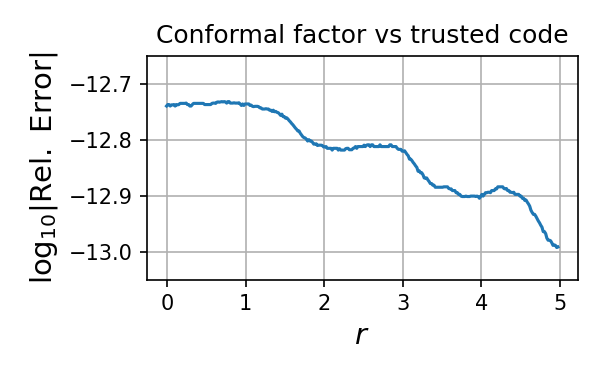

In [10]:
# Step 5.e: Plotting the relative error between the two initial data
# Step 5.e.i: Import required Python modules
import numpy as np                # NumPy: mathematical library for the Python programming language
import matplotlib.pyplot as plt   # Matplotlib: plotting library for the Python programming language
from IPython.display import Image # Image: Display images on Jupyter notebooks

# Step 5.e.ii: Read in the initial data files
rC ,sfC ,psiC  = np.loadtxt(os.path.join(Ccodesdir, "output.txt")).T
rPy,sfPy,psiPy = np.loadtxt(os.path.join(Ccodesdir, "output_trusted.txt")).T

# Step 5.e.iii: Generate the plot
fig = plt.figure(figsize=(4,2.5))

plt.grid()
plt.title("Conformal factor vs trusted code")
plt.ylim(-13.05,-12.65)
plt.xlabel(r"$r$",fontsize=14)
plt.ylabel(r"$\log_{10}{|\rm Rel.\ Error|}$",fontsize=14)
plt.plot(rC,np.log10(np.abs(1-psiC/psiPy)))
plt.tight_layout()

outfig = os.path.join(Ccodesdir,"validation.png")
plt.savefig(outfig,dpi=150,facecolor='white')
plt.close(fig)
Image(outfig)

<a id='output_to_pdf'></a>

# Step 6: Output this module as $\LaTeX$-formatted PDF file \[Back to [top](#toc)\]
$$\label{output_to_pdf}$$

The following code cell converts this Jupyter notebook into a proper, clickable $\LaTeX$-formatted PDF file. After the cell is successfully run, the generated PDF may be found in the root NRPy+ tutorial directory, with filename
[Tutorial-ADM_Initial_Data-ScalarField_Ccode.pdf](Tutorial-ADM_Initial_Data-ScalarField_Ccode.pdf) (Note that clicking on this link may not work; you may need to open the PDF file through another means.)

In [11]:
# Step 6: Output this module as LaTeX formatted PDF file
cmd.output_Jupyter_notebook_to_LaTeXed_PDF("Tutorial-ADM_Initial_Data-ScalarField_Ccode")

Created Tutorial-ADM_Initial_Data-ScalarField_Ccode.tex, and compiled LaTeX
    file to PDF file Tutorial-ADM_Initial_Data-ScalarField_Ccode.pdf
